# M-Pesa Transaction Auto-Categorisation: ML Engine (Base Model)

**Group:** 13 | **Members:** DENLEY KIPKOECH, NATASHA KEMUNTO, DENNIS MAIYO.

**Problem:** Kenyan informal traders mix business and personal money. The app reads a raw M-Pesa statement and predicts a budget category for each transaction from its `Details` text, `Paid In` and `Withdrawn`.

**ML task:** supervised multi-class text classification.
**Base model:** TF-IDF features + Logistic Regression (small, fast and interpretable, so it can run on-device).

**Workflow:** Explore raw data → Clean step by step → Attach labels → EDA → Base model → Validation → Compare other models

## 0. Setup and configuration

In [1]:
import re, io, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, f1_score
from build_labels import add_groups, CATEGORIES   # text-parsing rules for Details (build_labels.py must sit next to this notebook)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# ---- CONFIG: file and column names ----
RAW_PATH      = "mpesa_statement.ods"   
LABELS_PATH   = "merchant_labels.csv"   
COL_DETAILS   = "Details"
COL_IN        = "Paid In"
COL_OUT       = "Withdrawn"
COL_TIME      = "Completion Time"       
COL_STATUS    = "Transaction Status"    
COL_ID        = "Receipt No."           
LABEL_COL     = "Category"              
MIN_PER_CLASS = 10                      
GROUP_COL     = "merchant_key"          

## 1. Exploring the raw statement
First look at the file exactly as exported, before changing anything.

In [2]:
raw = pd.read_excel(RAW_PATH, engine="odf")
raw.columns = raw.columns.str.strip()
print("Shape:", raw.shape)
display(raw.head(8))
raw.info()

Shape: (3967, 7)


,Receipt No.,Completion Time,Details,Transaction Status,Paid In,Withdrawn,Balance
0,REF8MUC88I,2023-05-15 20:19:22,Customer Transfer Fuliza MPesato - 07******212...,Completed,NaN,-50,0
1,REF8MUC88I,2023-05-15 20:19:22,OverDraft of Credit Party,Completed,50,NaN,50
2,REF9MU2IWF,2023-05-15 20:17:21,Merchant Payment Fuliza M-Pesato 7384394 - DAM...,Completed,NaN,-30,0
3,REF9MU2IWF,2023-05-15 20:17:21,OverDraft of Credit Party,Completed,30,NaN,30
4,REF7MT5G7N,2023-05-15 20:10:35,Customer Transfer Fuliza MPesato - 2547******5...,Completed,NaN,-10,0
5,REF7MT5G7N,2023-05-15 20:10:35,OverDraft of Credit Party,Completed,10,NaN,10
6,REF6MSH7KM,2023-05-15 20:05:47,Merchant Payment Fuliza M-Pesato 671957 - FISH...,Completed,NaN,-70,0
7,REF6MSH7KM,2023-05-15 20:05:47,OverDraft of Credit Party,Completed,70,NaN,70


<class 'pandas.DataFrame'>
RangeIndex: 3967 entries, 0 to 3966
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Receipt No.         3885 non-null   str   
 1   Completion Time     3804 non-null   str   
 2   Details             3722 non-null   str   
 3   Transaction Status  3723 non-null   str   
 4   Paid In             1521 non-null   object
 5   Withdrawn           2290 non-null   object
 6   Balance             3723 non-null   object
dtypes: object(3), str(4)
memory usage: 526.5+ KB


### What is wrong with the raw file? (diagnostics)

In [3]:
is_txn = raw[COL_ID].astype(str).str.fullmatch(r"[A-Z0-9]{10}")
print("Rows that are real transactions:", int(is_txn.sum()), "| rows that are not:", int((~is_txn).sum()))
print("What the non-transaction rows contain in the receipt column:", raw.loc[~is_txn, COL_ID].value_counts().head(3).to_dict())
print("\nTransaction status values:", raw[COL_STATUS].value_counts().to_dict())
print("\nMissing values per column:\n" + raw.isna().sum().to_string())
print("\nMoney columns hold mixed types (dtype:", raw[COL_IN].dtype, "), e.g. Paid In:", raw[COL_IN].dropna().head(3).tolist(), "| Withdrawn:", raw[COL_OUT].dropna().head(3).tolist())
print("\nRows where Fuliza (M-Pesa overdraft) adds a second 'OverDraft of Credit Party' row to a payment:",
      int(raw[COL_DETAILS].astype(str).str.contains("OverDraft of Credit", case=False).sum()))
print("Exact duplicate rows (receipt + details + amounts):", int(raw.duplicated(subset=[COL_ID, COL_DETAILS, COL_IN, COL_OUT]).sum()))

Rows that are real transactions: 3635 | rows that are not: 332
What the non-transaction rows contain in the receipt column: {'Receipt No.': 88, 'Statement Verification Code': 81, 'KZ3FXNRZ': 81}

Transaction status values: {'Completed': 3632, 'Transaction Status': 88, 'Cancelled': 3}

Missing values per column:
Receipt No.             82
Completion Time        163
Details                245
Transaction Status     244
Paid In               2446
Withdrawn             1677
Balance                244

Money columns hold mixed types (dtype: object ), e.g. Paid In: [50, 30, 10] | Withdrawn: [-50, -30, -10]

Rows where Fuliza (M-Pesa overdraft) adds a second 'OverDraft of Credit Party' row to a payment: 924
Exact duplicate rows (receipt + details + amounts): 328


**Findings from exploration** (write the numbers from the output above in your own words):
1. The export is a converted PDF, so **page headers and verification-code lines are mixed in with the transactions**
2. Some transactions are **Cancelled/failed**
3. `Paid In` / `Withdrawn` are **mixed-type columns** (header text is mixed in with the numbers, so Python reads them as text), `Withdrawn` is **negative**, and a blank means zero
4. Every payment made with **Fuliza** has a second row ("OverDraft of Credit Party") for the loan that funded it: _how many?_ If kept, one payment would be counted twice.
5. `Details` is **free text** that mixes the transaction type, a till/paybill number, a (masked) phone number and the merchant name, often spelt inconsistently.

## 2. Cleaning step by step (exploration → final modelling dataset)
Each step has a reason; the running count shows what it removed.

| # | Step | Why |
|---|---|---|
| 1 | Remove header / footer / verification rows | They are not transactions |
| 2 | Keep **Completed** transactions only | Cancelled payments never moved money |
| 3 | Remove exact duplicate rows | Double counting. A payment and its charge share a receipt number, so duplicates are judged on receipt + details + amounts |
| 4 | Convert money columns to numbers | Mixed-type columns cannot be analysed; blank means 0 and withdrawals are negative |
| 5 | Parse `Details` into transaction type + merchant | The merchant is the signal the model needs |
| 6 | Merge spelling variants of one merchant | e.g. `KPLC PREPAID` and `KPLCPREPAID` are one merchant |
| 7 | Remove Fuliza loan-funding rows | They are not spending (see finding 4) |
| 8 | Attach the reviewed **category label** per merchant | The model needs a target to learn |
| 9 | Drop unlabelled rows and very rare categories | Cannot train or validate on a handful of rows |
| 10 | Normalise text, mask phone numbers and people's names | Reduces noise and removes personal data |

In [4]:
df = raw.copy()
log = {"raw rows": len(df)}

# 1. header / footer / verification rows
df = df[df[COL_ID].astype(str).str.fullmatch(r"[A-Z0-9]{10}")]
log["1 after removing non-transaction rows"] = len(df)

# 2. completed only
df = df[df[COL_STATUS].astype(str).str.strip().str.lower() == "completed"]
log["2 after keeping completed only"] = len(df)

# 3. exact duplicates
df = df.drop_duplicates(subset=[COL_ID, COL_DETAILS, COL_IN, COL_OUT])
log["3 after removing duplicates"] = len(df)

# 4. money columns -> numbers (blank = 0, withdrawals are negative so make them positive)
def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", "", regex=False), errors="coerce").fillna(0.0)
df["paid_in"], df["withdrawn"] = to_num(df[COL_IN]), to_num(df[COL_OUT]).abs()
df["amount"]     = df["paid_in"] + df["withdrawn"]
df["is_inflow"]  = (df["paid_in"] > 0).astype(int)
df["log_amount"] = np.log1p(df["amount"])
df[COL_DETAILS]  = df[COL_DETAILS].fillna("").astype(object).map(str).str.replace(r"\s+", " ", regex=True).str.strip()

# 5 + 6. parse Details into type + merchant, merge spelling variants (rules live in build_labels.py)
df = add_groups(df).reset_index(drop=True)
print("Spelling variants merged into one merchant, e.g.:")
shops = df[df["tx_group"].isin(["merchant", "paybill"])]
variants = shops.groupby("merchant_key")["name"].nunique().sort_values(ascending=False)
for k in variants.index[:3]:
    print("  ", k, "<-", df.loc[df["merchant_key"] == k, "name"].unique()[:3].tolist())

# 7. Fuliza loan-funding rows are not spending
df = df[df["tx_group"] != "fuliza_advance"]
log["7 after removing Fuliza loan rows"] = len(df)
print()
display(df.loc[df["tx_group"].isin(["merchant", "paybill"]), [COL_DETAILS, "tx_group", "name"]].sample(6, random_state=1))

Spelling variants merged into one merchant, e.g.:
   JAMBOSHOPANDMPESA <- ['JAMBOSHOPAND MPESA', 'JAMBO SHOPANDMPESA', 'JAMBO SHOPAND MPESA']
   DAMARISMORAAMORARA <- ['DAMARIS MORAAMORARA', 'DAMARIS MORAA MORARA', 'DAMARISMORAA MORARA']
   KONNEKTSMARTLIFELTD <- ['KONNEKT SMARTLIFE LTD', 'KONNEKT SMART LIFE LTD', 'KONNEKTSMART LIFE LTD']



,Details,tx_group,name
3382,Merchant Payment Fuliza M-Pesato 7158083 - SHE...,merchant,SHERIDANSWINES AND SPIRITS
3495,Merchant Payment Fuliza M-Pesato 7330872 - KAP...,merchant,KAPBRANDYWINES/SPIRITS/BEERS
3466,Merchant Payment Fuliza M-Pesato 7574811 - MAR...,merchant,MARGARET GICHIA
3000,Merchant Payment to 7688774 -EMAS FOOD FRY,merchant,EMAS FOOD FRY
1581,Merchant Payment Fuliza M-Pesato 7384394 - DAM...,merchant,DAMARIS MORAAMORARA
21,Merchant Payment Fuliza M-Pesato 7384394 - DAM...,merchant,DAMARIS MORAAMORARA


In [5]:
# 8. attach reviewed labels (one decision per merchant) from merchant_labels.csv
labels = pd.read_csv(LABELS_PATH).fillna({"final_category": ""})
bad = sorted(set(labels["final_category"]) - set(CATEGORIES) - {""})
assert not bad, f"Unknown category names in {LABELS_PATH}: {bad}"
df[LABEL_COL] = df["group_id"].map(labels.set_index("group_id")["final_category"]).fillna("")
print(f"Rows with a label: {(df[LABEL_COL] != '').sum()} of {len(df)}  ({(df[LABEL_COL] != '').mean()*100:.1f}%)")

# 9. drop unlabelled and very rare categories
df = df[df[LABEL_COL] != ""]
log["9a after dropping unlabelled rows"] = len(df)
counts = df[LABEL_COL].value_counts()
rare = counts[counts < MIN_PER_CLASS].index.tolist()
df = df[~df[LABEL_COL].isin(rare)].reset_index(drop=True)
log["9b after dropping rare categories"] = len(df)

# 10. text normalisation: lowercase, mask phones/long numbers, keep letters; people's names replaced by a generic word
def clean_details(s):
    s = str(s).lower()
    s = re.sub(r"(?:\+?254|0)7[\d\*]{7,8}", " phone ", s)
    s = re.sub(r"\d{5,}", " num ", s)
    s = re.sub(r"[^a-z\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()
generic = {"person_out": "customer transfer to person", "person_in": "funds received from person"}
df["text"] = np.where(df["tx_group"].isin(generic), df["tx_group"].map(generic), df[COL_DETAILS].apply(clean_details))
df["tx_type"] = df["tx_group"]

if COL_TIME and COL_TIME in df.columns:
    t = pd.to_datetime(df[COL_TIME], errors="coerce")
    df["hour"], df["weekday"] = t.dt.hour, t.dt.day_name()

print(pd.Series(log).to_string())
print("Dropped rare categories:", rare)
print("Missing values left:\n" + df[["text", "amount", LABEL_COL]].isna().sum().to_string())
display(df[[COL_DETAILS, "text", "amount", "is_inflow", "tx_type", LABEL_COL]].sample(6, random_state=2))

Rows with a label: 2227 of 2708  (82.2%)
raw rows                                 3967
1 after removing non-transaction rows    3635
2 after keeping completed only           3632
3 after removing duplicates              3632
7 after removing Fuliza loan rows        2708
9a after dropping unlabelled rows        2227
9b after dropping rare categories        2216
Dropped rare categories: ['Business - Stock', 'Business - Operating costs']
Missing values left:
text        0
amount      0
Category    0


,Details,text,amount,is_inflow,tx_type,Category
335,Pay Bill Online Fuliza M-Pesa to4093115 - KONN...,pay bill online fuliza m pesa to num konnekt s...,10.00,0,paybill,Personal - Bills & Utilities
1636,M-Shwari Withdraw,m shwari withdraw,10.00,1,other,"Savings, Loans & Fuliza"
786,Customer Transfer Fuliza MPesato - 2547******5...,customer transfer to person,10.00,0,person_out,Person-to-Person
1662,OD Loan Repayment to 232323 -M-PESA Overdraw,od loan repayment to num m pesa overdraw,50.00,0,fuliza_repayment,"Savings, Loans & Fuliza"
1367,OD Loan Repayment to 232323 -M-PESA Overdraw,od loan repayment to num m pesa overdraw,525.48,0,fuliza_repayment,"Savings, Loans & Fuliza"
1574,Funds received from -07******737 PATRICIACHEPN...,funds received from person,300.00,1,person_in,Person-to-Person


### Critical evaluation of the cleaning choices

- **Removing Fuliza loan rows** avoids double counting, but the statement's running balance can no longer be reconstructed from the remaining rows.
- **Merging spelling variants** by ignoring spaces fixes `KPLC PREPAID` / `KPLCPREPAID`, but could wrongly merge two different merchants with similar letters.
- **One label per merchant** is fast and consistent, but the same shop can serve both business and personal needs (e.g. a wholesaler also used for home groceries). The label then hides that.
- **Dropping unlabelled rows** keeps the training data clean but may bias the data towards the merchants we had time to label.
- **Dropping rare categories** (fewer than `MIN_PER_CLASS` rows) means the model cannot predict them at all. In this statement that removed the business categories, which is a limitation for the app's main purpose.
- **Masking people's names** protects privacy and stops the model memorising individuals, but it means the model cannot tell a supplier paid by phone number from a friend.
- **Label quality:** labels were assigned per merchant using keyword suggestions that a person confirmed or corrected (say who reviewed them and how many were changed). If labels were left as raw keyword suggestions, the model would just relearn those rules and the scores would be misleadingly high. Because every merchant shares one label, the **unseen-merchant test in section 6** is the honest measure.

## 3. Exploratory Data Analysis (EDA)

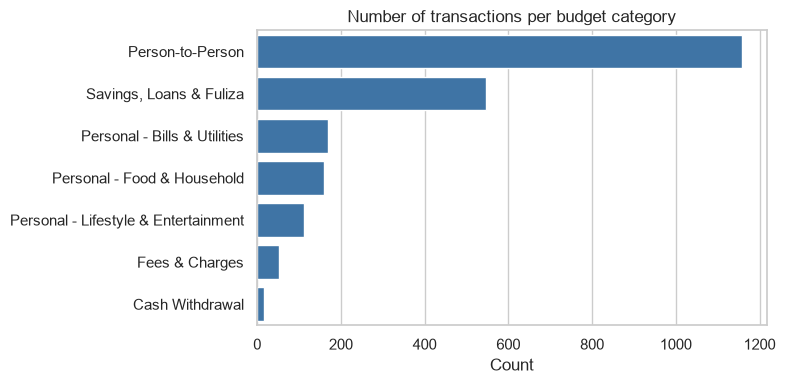

Category
Person-to-Person                        52.3
Savings, Loans & Fuliza                 24.7
Personal - Bills & Utilities             7.6
Personal - Food & Household              7.2
Personal - Lifestyle & Entertainment     5.1
Fees & Charges                           2.3
Cash Withdrawal                          0.7


In [6]:
# Observation 1: class balance
order = df[LABEL_COL].value_counts().index
plt.figure(figsize=(8, 4))
sns.countplot(y=df[LABEL_COL], order=order, color="#2E75B6")
plt.title("Number of transactions per budget category"); plt.xlabel("Count"); plt.ylabel("")
plt.tight_layout(); plt.show()
print((df[LABEL_COL].value_counts(normalize=True) * 100).round(1).to_string())

**Observation 1:** Person-to-Person (52.3%) and Savings, Loans & Fuliza (24.7%) dominate. Every other category is 8% or less, and Cash Withdrawal is under 1%. Accuracy alone would be misleading, so we use macro-F1(it treats every category as equal).

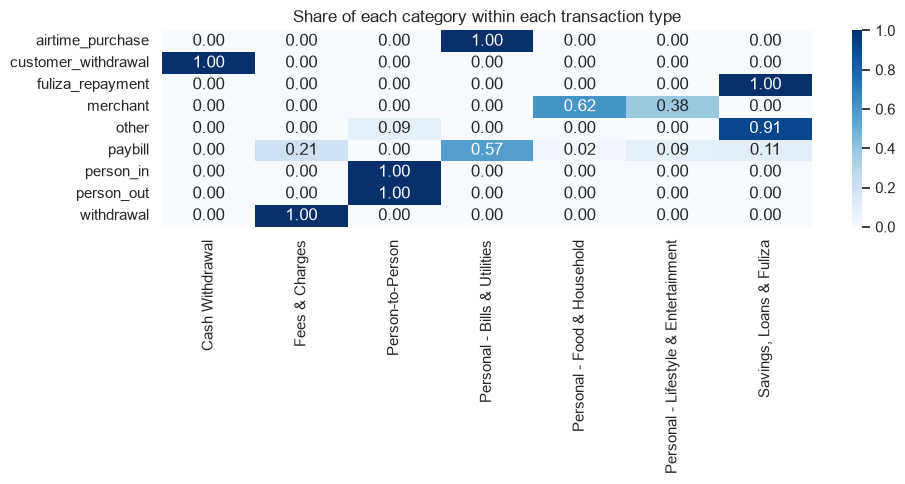

In [7]:
# Observation 2: transaction type vs category
ct = pd.crosstab(df["tx_type"], df[LABEL_COL], normalize="index")
plt.figure(figsize=(10, 5))
sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues")
plt.title("Share of each category within each transaction type"); plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); plt.show()

**Observation 2:** Transaction type almost decides the category: person transfers are 100% Person-to-Person, airtime is 100% Bills and Fuliza repayments are 100% Savings. Only merchant (62% Food, 38% Lifestyle) and paybill (57% Bills, 21% Fees) rows are mixed, so that’s where the model must read the merchant name.

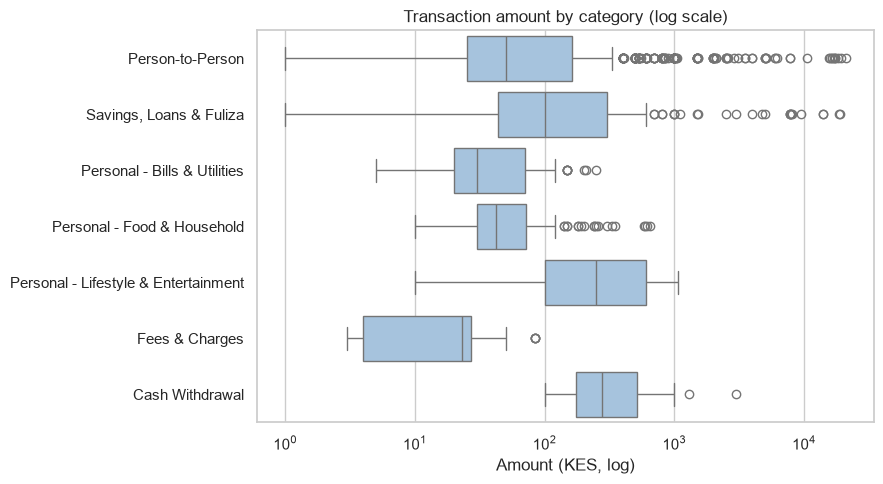

                                       count   mean     std    min    25%    50%    75%      max
Category                                                                                        
Cash Withdrawal                         16.0  544.0   737.0  100.0  175.0  275.0  515.0   3000.0
Fees & Charges                          52.0   22.0    23.0    3.0    4.0   23.0   27.0     85.0
Person-to-Person                      1159.0  391.0  1763.0    1.0   25.0   50.0  162.0  21046.0
Personal - Bills & Utilities           169.0   44.0    41.0    5.0   20.0   30.0   70.0    250.0
Personal - Food & Household            160.0   79.0   105.0   10.0   30.0   42.0   71.0    650.0
Personal - Lifestyle & Entertainment   113.0  350.0   292.0   10.0  100.0  250.0  600.0   1060.0
Savings, Loans & Fuliza                547.0  413.0  1671.0    0.0   40.0  100.0  300.0  18980.0


In [8]:
# Observation 3: amounts by category (log scale because amounts are heavily skewed)
plt.figure(figsize=(9, 5))
sns.boxplot(data=df[df["amount"] > 0], y=LABEL_COL, x="amount", order=order, color="#9DC3E6")
plt.xscale("log"); plt.title("Transaction amount by category (log scale)"); plt.xlabel("Amount (KES, log)"); plt.ylabel("")
plt.tight_layout(); plt.show()
print(df.groupby(LABEL_COL)["amount"].describe().round(0).to_string())

**Observation 3:** Amounts are very skewed, so we used a log scale. Typical spending is small (median KES 30 for Bills and 42 for Food), while Lifestyle (250) and Cash Withdrawal (275) are larger. Amount therefore helps tell categories apart.

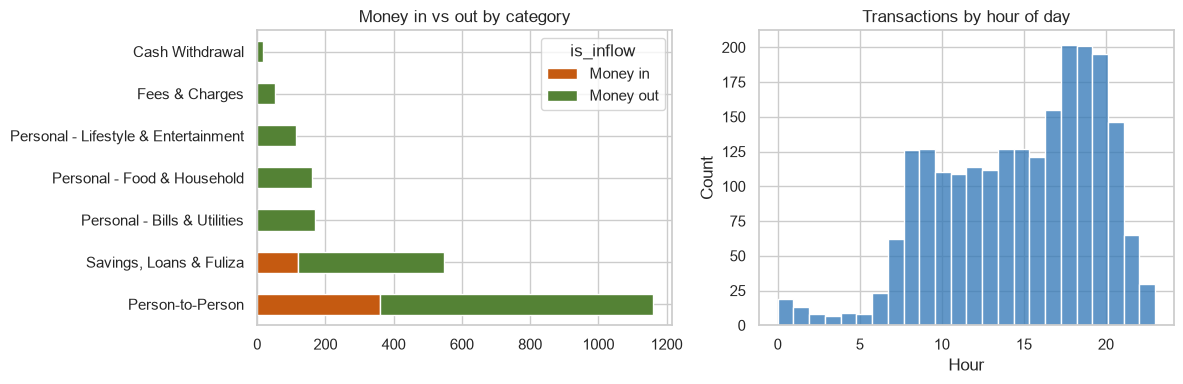

In [9]:
# Observation 4: money in vs money out, and timing
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pd.crosstab(df[LABEL_COL], df["is_inflow"].map({0: "Money out", 1: "Money in"})).loc[order].plot.barh(stacked=True, ax=ax[0], color=["#C55A11", "#548235"])
ax[0].set_title("Money in vs out by category"); ax[0].set_ylabel("")
if "hour" in df.columns:
    sns.histplot(df["hour"].dropna(), bins=24, ax=ax[1], color="#2E75B6"); ax[1].set_title("Transactions by hour of day"); ax[1].set_xlabel("Hour")
else:
    ax[1].axis("off")
plt.tight_layout(); plt.show()

**Observation 4:** Nearly all spending categories are money out. Money in appears only under Person-to-Person and Savings (M-Shwari withdrawals). Activity peaks between 17:00 and 20:00, with a steady plateau from 08:00 to 15:00 and very little at night.

In [10]:
# Observation 5 (extra): most common words per category
cv = CountVectorizer(stop_words=["num", "phone", "to", "from", "for", "of", "the", "and"], max_features=3000)
M = cv.fit_transform(df["text"]); vocab = np.array(cv.get_feature_names_out())
for cat in order:
    top = np.asarray(M[(df[LABEL_COL] == cat).values].sum(axis=0)).ravel().argsort()[::-1][:6]
    print(f"{cat:28s}", ", ".join(vocab[top]))

Person-to-Person             person, transfer, customer, received, funds, international
Savings, Loans & Fuliza      pesa, repayment, overdraw, od, loan, shwari
Personal - Bills & Utilities bill, acc, pay, fuliza, online, ltd
Personal - Food & Household  merchant, payment, fuliza, pesato, shop, fish
Personal - Lifestyle & Entertainment merchant, payment, spirits, kapbrandywines, fuliza, beers
Fees & Charges               charge, pay, bill, withdrawal, withfuliza, withdraw
Cash Withdrawal              withdrawal, agenttill, customer, at, shop, cooptalk


**Observation 5:** The top words for Food, Lifestyle and Bills include fuliza and pesato. These describe how the payment was made, not what was bought, so the real signal is the merchant name.

## 4. Base model: TF-IDF + Logistic Regression
**Why this model:** text is the main signal; TF-IDF turns the messy strings into numbers, and logistic regression is fast, works well on sparse text, shows which words drive a prediction, and its small size suits **on-device** use.

**Features:** word and character n-grams of the cleaned `Details` (character n-grams cope with typos and odd spellings like `WAKULIMA WHLSALE`), plus `log_amount` and `is_inflow`.
**Class imbalance:** `class_weight="balanced"`. **Split:** 80/20, stratified, so every category appears in both parts.

### Modelling approach (Q3)
1. **Target and features:** the target is the budget category. The features are the cleaned `Details` text, the log of the amount, and whether money came in or went out.
2. **Split:** 80% training, 20% test, stratified so every category appears in both. The test set is not touched until the final check.
3. **Pipeline:** TF-IDF turns the text into numbers (word pairs plus character patterns, so misspellings still match). The amount features are scaled to 0-1. Logistic Regression then predicts the category.
4. **Class imbalance:** `class_weight="balanced"` so small categories are not ignored.
5. **Validity checks (section 5):** stratified 5-fold cross-validation on the training set; regularisation tuning of C; a hold-out test set scored with macro-F1; a confusion matrix and error analysis; a test on merchants the model has never seen (section 6).
6. **Avoiding leakage:** TF-IDF and scaling sit inside the pipeline, so each fold learns them from its own training part only and never sees its validation rows.

In [11]:
FEATURES = ["text", "log_amount", "is_inflow"]
X, y = df[FEATURES], df[LABEL_COL]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)

def make_preprocessor():
    return ColumnTransformer([
        ("word", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), "text"),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True, min_df=2), "text"),
        ("num",  MinMaxScaler(), ["log_amount", "is_inflow"]),
    ])

base = Pipeline([("prep", make_preprocessor()),
                 ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))])
n_splits = int(max(2, min(5, y_train.value_counts().min())))
cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
print("CV folds:", n_splits)

Train: (1772, 3) Test: (444, 3)
CV folds: 5


## 5. Validating the base model
Three checks so the result can be trusted:
1. **Stratified k-fold cross-validation** (on the training set only) to see how stable the score is.
2. **Regularisation tuning:** search the strength `C` of the logistic regression (smaller C = stronger regularisation) so the model does not overfit.
3. **Hold-out test set** that the model never saw, reported with **macro-F1** (treats every category equally) and a confusion matrix.

Base model CV macro-F1: 0.989 (+/- 0.007)  folds: [0.983 0.981 0.993 1.    0.99 ]
Best C: 10 | best CV macro-F1: 0.996


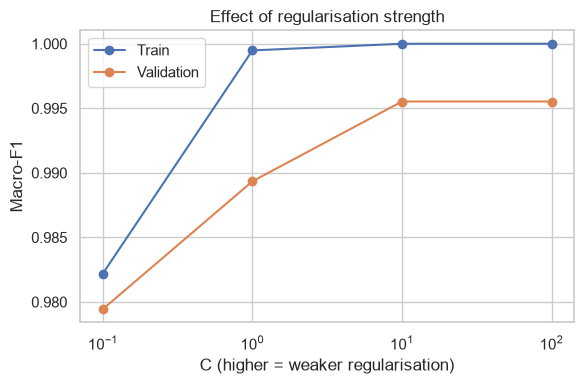

In [12]:
# 1) cross-validation of the untuned base model
cv_scores = cross_val_score(base, X_train, y_train, cv=cv, scoring="f1_macro")
print(f"Base model CV macro-F1: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})  folds: {cv_scores.round(3)}")

# 2) regularisation: tune C
grid = GridSearchCV(base, {"clf__C": [0.1, 1, 10, 100]}, cv=cv, scoring="f1_macro", n_jobs=-1, return_train_score=True)
grid.fit(X_train, y_train)
print("Best C:", grid.best_params_["clf__C"], "| best CV macro-F1:", round(grid.best_score_, 3))

res = pd.DataFrame(grid.cv_results_)
plt.figure(figsize=(6, 4))
plt.plot(res["param_clf__C"].astype(float), res["mean_train_score"], marker="o", label="Train")
plt.plot(res["param_clf__C"].astype(float), res["mean_test_score"],  marker="o", label="Validation")
plt.xscale("log"); plt.xlabel("C (higher = weaker regularisation)"); plt.ylabel("Macro-F1"); plt.legend()
plt.title("Effect of regularisation strength"); plt.tight_layout(); plt.show()

**Reading the curve:** Validation score rises as C increases and flattens from C = 10, while the training score is about 1.0. The gap is small and the validation score doesn’t drop, so there’s no sign of overfitting. We chose C = 10: the same validation score as C = 100 with stronger regularisation.

Test accuracy: 0.991 | Test macro-F1: 0.979

                                      precision    recall  f1-score   support

                     Cash Withdrawal       1.00      1.00      1.00         3
                      Fees & Charges       1.00      1.00      1.00        10
                    Person-to-Person       1.00      1.00      1.00       232
        Personal - Bills & Utilities       1.00      1.00      1.00        34
         Personal - Food & Household       0.94      0.94      0.94        32
Personal - Lifestyle & Entertainment       0.91      0.91      0.91        23
             Savings, Loans & Fuliza       1.00      1.00      1.00       110

                            accuracy                           0.99       444
                           macro avg       0.98      0.98      0.98       444
                        weighted avg       0.99      0.99      0.99       444



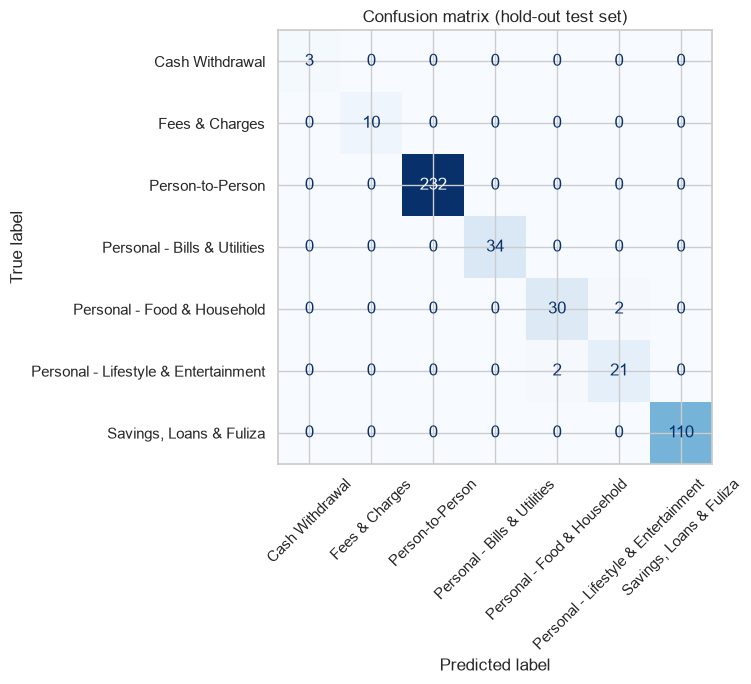

In [13]:
# 3) hold-out test performance
best = grid.best_estimator_
pred = best.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, pred):.3f} | Test macro-F1: {f1_score(y_test, pred, average='macro'):.3f}\n")
print(classification_report(y_test, pred, zero_division=0))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Confusion matrix (hold-out test set)"); plt.tight_layout(); plt.show()

In [14]:
# Error analysis: look at what the model gets wrong
errors = X_test.assign(actual=y_test, predicted=pred)
errors = errors[errors["actual"] != errors["predicted"]]
print(f"{len(errors)} wrong out of {len(X_test)}")
display(errors[["text", "log_amount", "actual", "predicted"]].head(10))

4 wrong out of 444


,text,log_amount,actual,predicted
2147,merchant payment fuliza m pesato num frakaz pub,5.303305,Personal - Lifestyle & Entertainment,Personal - Food & Household
1980,pay bill to num eldoret makuti bar restaurant acc,4.709530,Personal - Food & Household,Personal - Lifestyle & Entertainment
1983,pay bill to num eldoret makuti bar restaurant acc,5.484797,Personal - Food & Household,Personal - Lifestyle & Entertainment
1627,merchant payment fuliza m pesato num frakaz pub,5.017280,Personal - Lifestyle & Entertainment,Personal - Food & Household


**Interpretation:** Person-to-Person, Savings, Bills and Fees were predicted perfectly. The only mistakes (4 of 444) were Food & Household confused with Lifestyle & Entertainment, for places like ‘bar restaurant’ and ‘pub’ that fit both.

## 6. Other methods to validate the result (Q4)
To check that the base model is a sensible choice, I trained other models on the **same features and the same split**, and compared them using the same cross-validation. Because the app runs **on-device**, I also compare model **size** and **prediction speed**, not only accuracy.

,Model,CV macro-F1,CV std,Test macro-F1,Test accuracy,ms / prediction,Size (KB)
0,Linear SVM,0.997,0.005,0.979,0.991,0.281,178.4
1,Logistic Regression (base),0.996,0.005,0.979,0.991,0.331,178.5
2,Random Forest,0.993,0.004,0.978,0.989,0.504,1135.5
3,Complement Naive Bayes,0.983,0.012,0.971,0.984,0.229,329.0


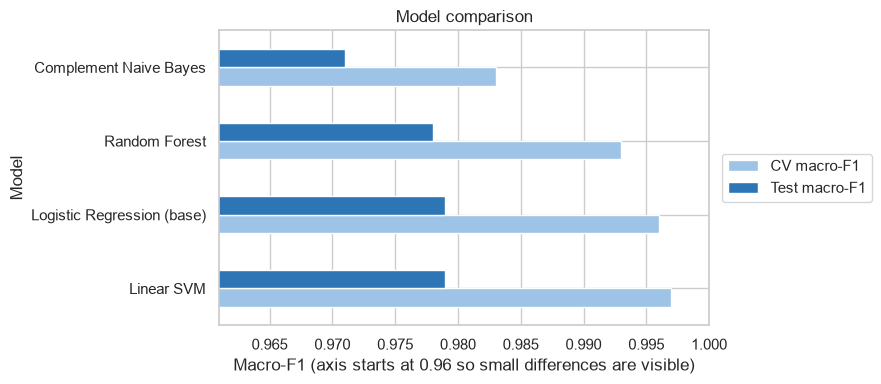

In [15]:
candidates = {
    "Logistic Regression (base)": LogisticRegression(max_iter=3000, class_weight="balanced", C=grid.best_params_["clf__C"]),
    "Linear SVM":                 LinearSVC(class_weight="balanced"),
    "Complement Naive Bayes":     ComplementNB(),
    "Random Forest":              RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
}
rows = []
for name, clf in candidates.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    cvs = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro")
    pipe.fit(X_train, y_train)
    t0 = time.perf_counter(); p = pipe.predict(X_test); ms = (time.perf_counter() - t0) / len(X_test) * 1000
    buf = io.BytesIO(); joblib.dump(pipe, buf)
    rows.append({"Model": name, "CV macro-F1": round(cvs.mean(), 3), "CV std": round(cvs.std(), 3),
                 "Test macro-F1": round(f1_score(y_test, p, average="macro"), 3),
                 "Test accuracy": round(accuracy_score(y_test, p), 3),
                 "ms / prediction": round(ms, 3), "Size (KB)": round(buf.getbuffer().nbytes / 1024, 1)})
results = pd.DataFrame(rows).sort_values("CV macro-F1", ascending=False).reset_index(drop=True)
display(results)

ax = results.set_index("Model")[["CV macro-F1", "Test macro-F1"]].plot.barh(figsize=(9, 4), color=["#9DC3E6", "#2E75B6"])
lo = results[["CV macro-F1", "Test macro-F1"]].min().min() - 0.01
ax.set_xlim(max(0, lo), 1.0); ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.xlabel(f"Macro-F1 (axis starts at {max(0, lo):.2f} so small differences are visible)"); plt.title("Model comparison"); plt.tight_layout(); plt.show()

In [16]:
# Unseen-merchant validation: each shop / paybill is held out as a whole merchant, like a new user's first visit.
# Fixed-wording rows (transfers, fees, Fuliza, withdrawals) are not merchants, so they stay spread across the folds.
if GROUP_COL and GROUP_COL in df.columns:
    from sklearn.model_selection import GroupKFold, cross_val_predict
    sub = df.loc[X_train.index]
    is_shop = sub["tx_group"].isin(["merchant", "paybill"]).values
    groups = np.where(is_shop, sub[GROUP_COL], "row" + sub.index.astype(str))
    gcv = GroupKFold(n_splits=5)
    g_scores = cross_val_score(best, X_train, y_train, cv=gcv, groups=groups, scoring="f1_macro")
    oof = cross_val_predict(best, X_train, y_train, cv=gcv, groups=groups)
    print(f"Random stratified CV macro-F1 (same merchants in train and validation): {grid.best_score_:.3f}")
    print(f"Unseen-merchant CV macro-F1 (shops held out):                           {g_scores.mean():.3f} (+/- {g_scores.std():.3f})")
    print(f"Accuracy on shop/paybill rows whose merchant was never seen:            {accuracy_score(y_train[is_shop], oof[is_shop]):.3f}  (n = {int(is_shop.sum())})")
else:
    print("No merchant column found, so this check was skipped.")

Random stratified CV macro-F1 (same merchants in train and validation): 0.996
Unseen-merchant CV macro-F1 (shops held out):                           0.909 (+/- 0.061)
Accuracy on shop/paybill rows whose merchant was never seen:            0.839  (n = 341)


**Comparison summary:** All four models score within about 0.98 to 1.00 of each other, and Logistic Regression and Linear SVM are effectively tied (the CV spread is about 0.005). We keep Logistic Regression because it’s small (178 KB), fast (about 0.23 ms per prediction), explainable, and gives probabilities, so the app can say ‘not sure’. Random Forest is six times bigger and slower with no gain.

**Further validation ideas (description only, per the brief):**
- **Unseen-merchant test (done above):** whole merchants are kept out of training with `GroupKFold`. If this score is much lower than the random-CV score, the model is partly memorising merchant names rather than learning from the wording.
- **Per-trader split:** train on some traders and test on others, to check it generalises across people.
- **Label-agreement check:** have a second person re-label a sample and compare, to estimate the ceiling for accuracy.

### How the base model's results are further validated (Q4)
| Method | What it checks | Status |
|---|---|---|
| Other models, same process (Linear SVM, Naive Bayes, Random Forest) | Is Logistic Regression a sensible choice, or does another model do clearly better? | Done: all within about 0.015 macro-F1 of each other |
| Unseen-merchant test (GroupKFold) | Does it work on shops it has never seen, or only memorised names? | Done: about 0.91 macro-F1 |
| Time-based split | Train on earlier months, test on later ones, as real use would | Planned: the statement covers about a year |
| Per-trader split | Does it work for a different person's statement? | Planned: needs more traders' data |
| Label-agreement check | A second person re-labels a sample; their agreement sets a ceiling for any model's accuracy | Planned |

**Approach:** every comparison model follows the same pipeline (same cleaning, the same train/test split, the same features and the same 5-fold cross-validation), so differences in score come from the model and not from the setup. We compare macro-F1, speed and file size, because the app must run on a phone.

## 7. Conclusion
We classified M-Pesa transactions into budget categories with TF-IDF and Logistic Regression: test macro-F1 0.979, and about 0.915 on merchants it had never seen. The main weakness is categories that overlap (Food vs Lifestyle). The main limitation is that our statement has almost no business transactions, so the business-versus-personal split isn’t demonstrated yet. Next step: label a trader’s statement and test on-device.

In [17]:
# Save the final model (optional: this is what the mobile app would convert/load)
joblib.dump(best, "category_model.joblib")
print("Saved category_model.joblib")

Saved category_model.joblib
